# Convert and Optimize ByteTrack (YOLOX-X + BYTETracker) multi-object tracking with OpenVINO™

Multi-object tracking is a key component of video analytics, retail and traffic analytics, robotics and sports
analysis. [ByteTrack](https://github.com/FoundationVision/ByteTrack) is a tracking-by-detection tracker:
* a **YOLOX-X** detector (800×1440, ~99 M parameters) finds the people in every frame;
* the **BYTETracker** associates the detections over time. It uses *all* detection boxes: high-score boxes first,
  then low-score boxes are used to recover occluded objects. A Kalman filter and IoU matching are used, with no
  appearance re-ID.

Only the detector is a neural network, so only the detector is converted and quantized. The tracker stays on the host
with its configuration.

This tutorial converts and optimizes the detector with OpenVINO:
1. Take the tracking config and the **PyTorch FP32 model** exported by
   [ByteTrack_PyTorch_Enablement.ipynb](./ByteTrack_PyTorch_Enablement.ipynb).
2. Convert to **OpenVINO IR FP32**, then convert the FP32 IR to **FP16**.
3. Check accuracy (MOTA / IDF1 on MOT17 val-half) and run both precisions on a video.
4. Quantize FP32 IR → **INT8** with NNCF post-training quantization. If MOTA drops by more than 2 points, use
   `nncf.quantize_with_accuracy_control`.
5. Run INT8 on the video and measure **average latency and FPS with `benchmark_app`**.
6. Compare every OpenVINO precision with PyTorch FP32 / FP16.

> **Environment:** a Python 3 kernel with PyTorch (XPU build for Intel GPUs, or CPU), OpenVINO ≥ 2026.0, NNCF ≥ 3.4 and the
> packages in [requirements.txt](./requirements.txt). All paths are relative to this repository (see
> [bytetrack_nb_utils.py](./bytetrack_nb_utils.py): weights, MOT17 and the videos are looked up in the repo and its
> parent folder, or set `BYTETRACK_WEIGHTS`, `MOT17_TRAIN`, `VIDEO_1`).
>
> Run the PyTorch enablement notebook first.

#### Table of contents:

- [Prerequisites](#Prerequisites)
- [Get PyTorch model and tracking config](#Get-PyTorch-model-and-tracking-config)
- [Convert model to OpenVINO IR](#Convert-model-to-OpenVINO-IR)
    - [FP32 IR](#FP32-IR)
    - [FP32 IR to FP16 IR](#FP32-IR-to-FP16-IR)
- [Select inference device](#Select-inference-device)
- [Verify model inference](#Verify-model-inference)
- [Accuracy of OpenVINO FP32 and FP16](#Accuracy-of-OpenVINO-FP32-and-FP16)
- [Run FP32 and FP16 on a video](#Run-FP32-and-FP16-on-a-video)
- [Optimize model using NNCF Post-training Quantization API](#Optimize-model-using-NNCF-Post-training-Quantization-API)
    - [Validate Quantized model inference](#Validate-Quantized-model-inference)
    - [Run INT8 on the video](#Run-INT8-on-the-video)
- [Compare performance of the models with benchmark_app](#Compare-performance-of-the-models-with-benchmark_app)
- [Accuracy and performance: OpenVINO vs PyTorch](#Accuracy-and-performance:-OpenVINO-vs-PyTorch)

## Prerequisites
[back to top ⬆️](#Table-of-contents:)

Same environment as the PyTorch notebook (uncomment the `%pip` line on first use).

In [1]:
# %pip install -q -r requirements.txt
import sys, os, json, time, shutil
from pathlib import Path
import numpy as np, cv2, torch
import openvino as ov
import nncf
import bytetrack_nb_utils as U
from IPython.display import Image, display, Markdown

core = ov.Core()
print("OpenVINO", ov.__version__, "| NNCF", nncf.__version__, "| torch", torch.__version__)
print("devices:", {d: core.get_property(d, "FULL_DEVICE_NAME") for d in core.available_devices})
OUT = Path("results")                                    # relative to this notebook
(OUT / "images").mkdir(parents=True, exist_ok=True)

OpenVINO 2026.4.0-22701-36ef3d68c9f | NNCF 3.4.0 | torch 2.14.0.dev20260809+xpu
devices: {'CPU': 'Intel(R) Core(TM) Ultra X7 358H', 'GPU': 'Intel(R) Arc(TM) B390 GPU (iGPU)', 'NPU': 'Intel(R) AI Boost'}


## Get PyTorch model and tracking config
[back to top ⬆️](#Table-of-contents:)

Both come from the PyTorch enablement notebook (`notebooks/artifacts/`):
* `bytetrack_x_mot17_fp32_fused.pt`: the **FP32** PyTorch detector, with Conv+BN fused and the box decode in the graph;
* `bytetrack_config.json`: **the tracking config**.

**Is a tracking config needed for OpenVINO?** Yes. `track_thresh`, `match_thresh`, `track_buffer`, `min_box_area`,
the aspect-ratio filter, the per-sequence overrides, the NMS / confidence thresholds and the pre-processing are
**not in the weights**. They are not in the IR graph either. OpenVINO only replaces the network, so the host pipeline
must use the same config. It is embedded into the IR `rt_info` and also saved next to every IR.

In [2]:
ART = Path("artifacts")
assert (ART / "bytetrack_x_mot17_fp32_fused.pt").exists(), "run ByteTrack_PyTorch_Enablement.ipynb first"
cfg = json.load(open(ART / "bytetrack_config.json"))
pt_results = json.load(open(ART / "pytorch_results.json"))
pt_model = torch.load(ART / "bytetrack_x_mot17_fp32_fused.pt", map_location="cpu", weights_only=False).eval()
INPUT_HW = tuple(cfg["detector"]["input_size_hw"])
print(type(pt_model).__name__, f"{sum(p.numel() for p in pt_model.parameters()) / 1e6:.2f} M params | input {INPUT_HW}")
print("tracker:", {k: v for k, v in cfg["tracker"].items() if not isinstance(v, str)})
print("PyTorch baselines:", {k: (round(v["MOTA"], 2), round(v["IDF1"], 2)) for k, v in pt_results["accuracy"].items()})

YoloxDecoded 98.94 M params | input (800, 1440)
tracker: {'track_thresh': 0.6, 'low_score_thresh': 0.1, 'match_thresh_first_assoc': 0.9, 'match_thresh_second_assoc': 0.5, 'match_thresh_unconfirmed': 0.7, 'fuse_score': True, 'track_buffer': 30, 'frame_rate': 30, 'min_box_area': 100, 'max_aspect_ratio_w_over_h': 1.6, 'mot20': False}
PyTorch baselines: {'PT_FP32': (90.2, 86.57), 'PT_FP16': (90.23, 86.47)}


## Convert model to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR) format. `ov.convert_model`
traces the FP32 module, and `ov.save_model` serializes it. The first step produces an **FP32 IR**. The FP16 IR is then
produced from the **saved FP32 IR**: weights are compressed to FP16, and the inputs/outputs stay f32.

### FP32 IR
[back to top ⬆️](#Table-of-contents:)

In [3]:
IR_DIR = Path("ov_models")                                       # relative to this notebook
det_model_path = IR_DIR / "FP32" / "bytetrack_x_mot17.xml"           # FP32 IR = source for FP16 and INT8
fp16_model_path = IR_DIR / "FP16" / "bytetrack_x_mot17.xml"

def save_with_config(model, xml, compress_to_fp16):
    model.set_rt_info(json.dumps(cfg), ["bytetrack_config"])            # tracking config travels with the IR
    xml.parent.mkdir(parents=True, exist_ok=True)
    ov.save_model(model, str(xml), compress_to_fp16=compress_to_fp16)
    shutil.copy(ART / "bytetrack_config.json", xml.parent / "bytetrack_config.json")

import warnings
if not det_model_path.exists():
    t = time.perf_counter()
    with warnings.catch_warnings():                                 # silence torch.jit.trace deprecation noise
        warnings.simplefilter("ignore")
        ov_model = ov.convert_model(pt_model, example_input=torch.zeros(1, 3, *INPUT_HW), input=[ov.PartialShape([1, 3, *INPUT_HW])])
    ov_model.inputs[0].get_tensor().set_names({"images"})
    ov_model.outputs[0].get_tensor().set_names({"output"})
    save_with_config(ov_model, det_model_path, compress_to_fp16=False)
    print(f"converted in {time.perf_counter() - t:.1f}s")
print(f"FP32 IR: {det_model_path} ({det_model_path.with_suffix('.bin').stat().st_size / 1e6:.0f} MB)")

FP32 IR: ov_models/FP32/bytetrack_x_mot17.xml (396 MB)


### FP32 IR to FP16 IR
[back to top ⬆️](#Table-of-contents:)

In [4]:
if not fp16_model_path.exists():
    save_with_config(core.read_model(det_model_path), fp16_model_path, compress_to_fp16=True)
m16 = core.read_model(fp16_model_path)
print(f"FP16 IR: {fp16_model_path} ({fp16_model_path.with_suffix('.bin').stat().st_size / 1e6:.0f} MB) | "
      f"input {m16.input(0).get_element_type()} {m16.input(0).get_partial_shape()} | rt_info config: {m16.has_rt_info(['bytetrack_config'])}")

FP16 IR: ov_models/FP16/bytetrack_x_mot17.xml (198 MB) | input <Type: 'float32'> [1,3,800,1440] | rt_info config: True


## Select inference device
[back to top ⬆️](#Table-of-contents:)

Select the device from the dropdown list for running inference with OpenVINO.

> **FP32 on GPU:** the GPU plugin executes an FP32 IR in **f16** by default. A true FP32 run, comparable to PyTorch
> FP32, needs `INFERENCE_PRECISION_HINT=f32`, which is `-infer_precision f32` in `benchmark_app`. All "OV FP32" numbers
> below use it.

In [5]:
import ipywidgets as widgets
device = widgets.Dropdown(options=core.available_devices + ["AUTO"], value="GPU" if "GPU" in core.available_devices else "CPU",
                          description="Device:")
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='GPU')

## Verify model inference
[back to top ⬆️](#Table-of-contents:)

One MOT17-09 frame is run through both IRs and compared with the PyTorch FP32 output (CPU reference). Three checks:
* cosine of the raw `[1, 23625, 6]` output. It is dominated by box sizes of the ~23k background anchors, whose
  `exp(w,h)` can be huge;
* cosine of the score map (obj×cls), which is what decides the detections;
* the number of detections after NMS.

PyTorch FP32 (CPU) detections: 15


OV FP32: exec precision f32  |  193.3 ms/frame | cosine vs PT FP32: raw 1.0000000, scores 1.0000000 | detections 15


OV FP16: exec precision f16  |   28.0 ms/frame | cosine vs PT FP32: raw 0.9999982, scores 1.0000000 | detections 15


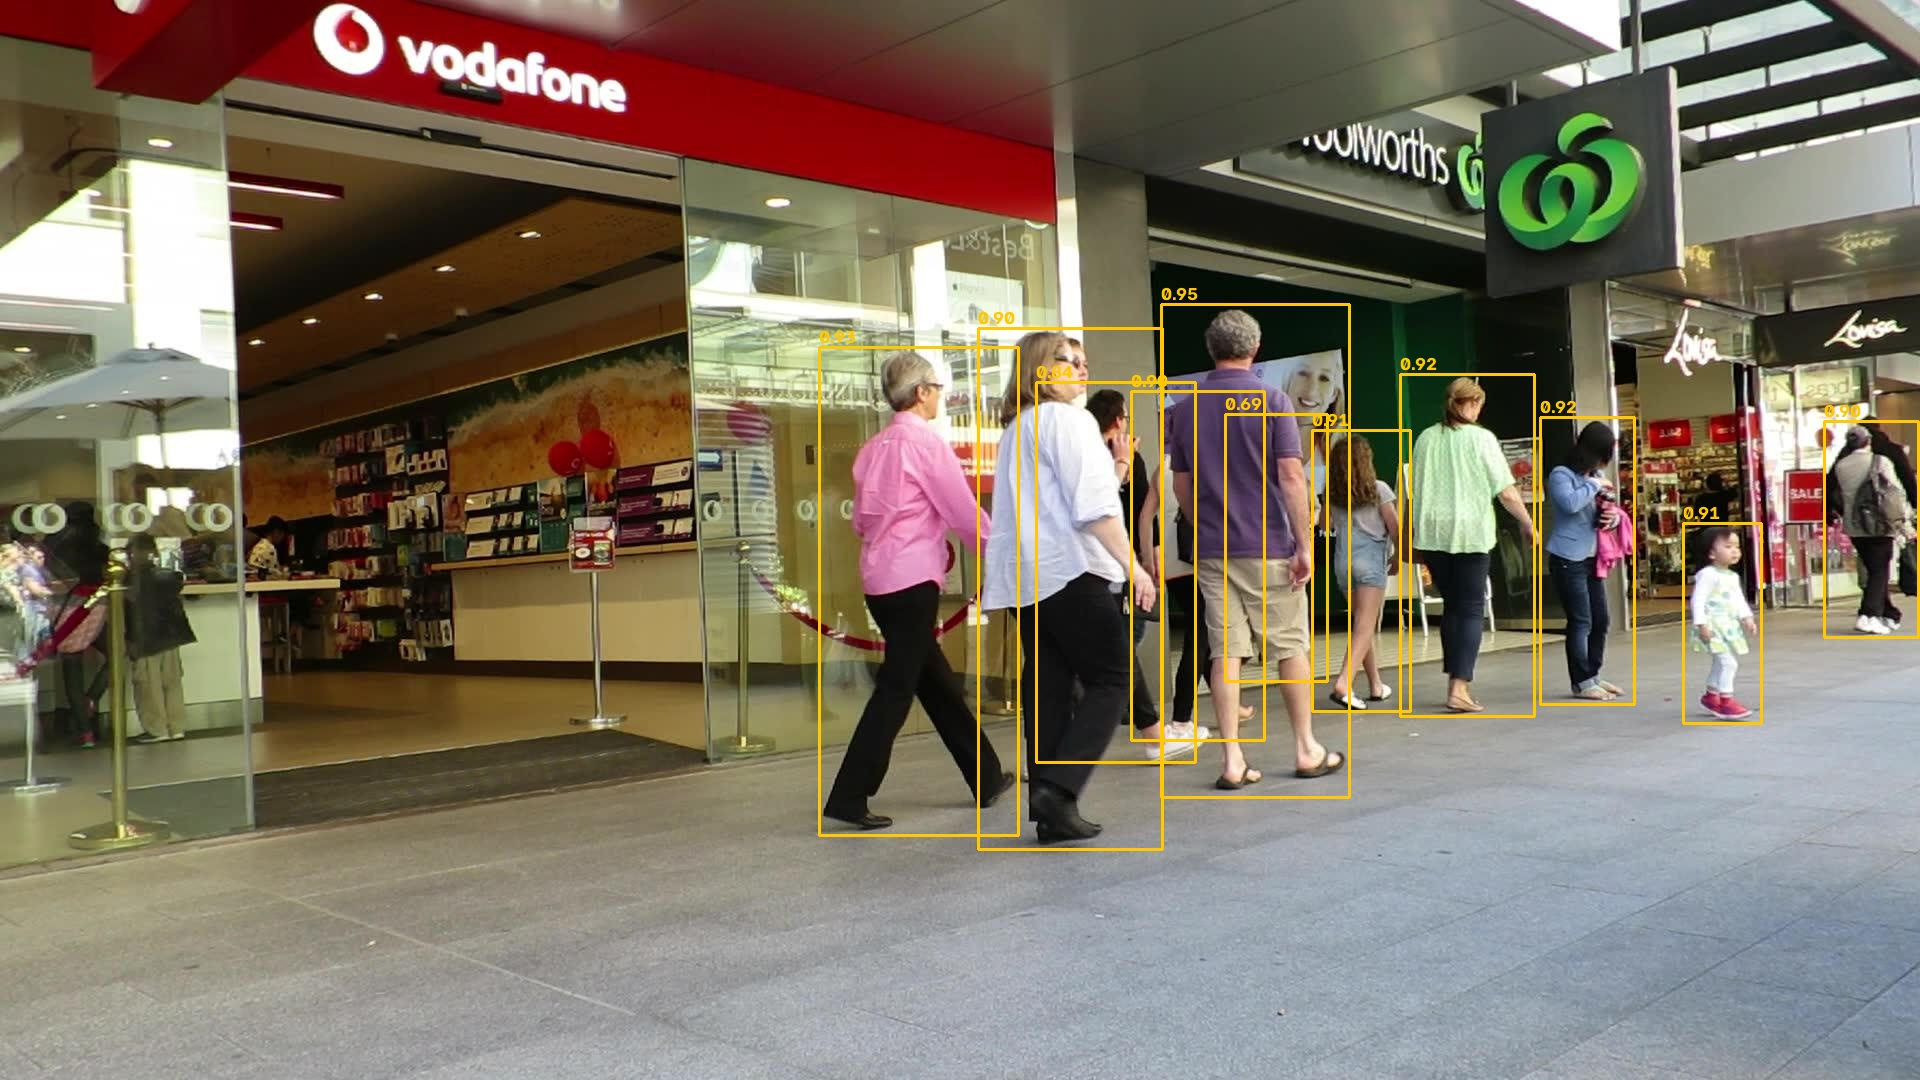

In [6]:
FP32_PROPS = {"INFERENCE_PRECISION_HINT": "f32"} if device.value.startswith("GPU") else {}
ov_fp32 = U.ov_runner(core, str(det_model_path), device.value, **FP32_PROPS)
ov_fp16 = U.ov_runner(core, str(fp16_model_path), device.value)

seq = U.mot17_val_half(["MOT17-09-FRCNN"])[0]
img0 = cv2.imread(seq["frames"][0][1]); x0, r0 = U.preprocess(img0, cfg)
with torch.inference_mode():
    ref = pt_model(torch.from_numpy(x0)).numpy()
print(f"PyTorch FP32 (CPU) detections: {len(U.postprocess(ref, cfg))}")
for name, run in (("OV FP32", ov_fp32), ("OV FP16", ov_fp16)):
    y, ms = U.timeit(run, x0, n=10)
    print(f"{name}: exec precision {run.exec_precision:4s} | {ms:6.1f} ms/frame | cosine vs PT FP32: raw {U.cosine(y, ref):.7f}, "
          f"scores {U.score_cosine(y, ref):.7f} | detections {len(U.postprocess(y, cfg))}")
cv2.imwrite(str(OUT / "images/ov_fp16_detections.jpg"), U.draw_dets(img0, U.postprocess(ov_fp16(x0), cfg), r0))
display(Image(str(OUT / "images/ov_fp16_detections.jpg"), width=900))

## Accuracy of OpenVINO FP32 and FP16
[back to top ⬆️](#Table-of-contents:)

Same MOT17 val-half protocol, host pipeline and tracker config as the PyTorch notebook. Only the network backend differs.

In [7]:
ACC_SEQS = None if isinstance(pt_results["accuracy_sequences"], str) else pt_results["accuracy_sequences"]   # same sequences as PyTorch
acc = dict(pt_results["accuracy"])
for tag, run in (("OV_FP32", ov_fp32), ("OV_FP16", ov_fp16)):
    acc[tag] = U.mot_eval(run, cfg, tag, seqs=ACC_SEQS, verbose=False)
ref_acc = acc["PT_FP32"]
rows = ["| Config | MOTA | ΔMOTA vs PT FP32 | IDF1 | ΔIDF1 | IDs | FP | FN |", "|---|---|---|---|---|---|---|---|"]
for k, m in acc.items():
    rows.append(f"| {k} | {m['MOTA']:.2f} | {m['MOTA'] - ref_acc['MOTA']:+.2f} | {m['IDF1']:.2f} | {m['IDF1'] - ref_acc['IDF1']:+.2f} | {m['IDs']} | {m['FP']} | {m['FN']} |")
display(Markdown("\n".join(rows)))

| Config | MOTA | ΔMOTA vs PT FP32 | IDF1 | ΔIDF1 | IDs | FP | FN |
|---|---|---|---|---|---|---|---|
| PT_FP32 | 90.20 | +0.00 | 86.57 | +0.00 | 175 | 1058 | 4050 |
| PT_FP16 | 90.23 | +0.04 | 86.47 | -0.10 | 180 | 1058 | 4025 |
| OV_FP32 | 90.20 | +0.00 | 86.57 | +0.00 | 175 | 1058 | 4050 |
| OV_FP16 | 90.24 | +0.05 | 86.83 | +0.26 | 179 | 1042 | 4037 |

## Run FP32 and FP16 on a video
[back to top ⬆️](#Table-of-contents:)

`JK_Standing_Next2U.mp4` is tracked with the same video tracker parameters as in the PyTorch notebook. The tracks are
scored **against the PyTorch FP32 tracks** (100 = identical tracking output).

OV_FP32 {'tag': 'OV_FP32', 'frames': 900, 'shots': 8, 'unique_ids': 59, 'mean_tracks_per_frame': 6.02, 'cuts_with_ids_carried_across': 3, 'detector_ms_per_frame': 194.03, 'pipeline_fps': 4.56, 'video': 'JK_Standing_Next2U.mp4', 'fps': 30.0, 'IDF1_vs_ref': 88.03, 'MOTA_vs_ref': 95.98, 'IDsw_vs_ref': 20}


OV_FP16 {'tag': 'OV_FP16', 'frames': 900, 'shots': 8, 'unique_ids': 59, 'mean_tracks_per_frame': 6.02, 'cuts_with_ids_carried_across': 3, 'detector_ms_per_frame': 29.0, 'pipeline_fps': 18.49, 'video': 'JK_Standing_Next2U.mp4', 'fps': 30.0, 'IDF1_vs_ref': 86.07, 'MOTA_vs_ref': 95.91, 'IDsw_vs_ref': 22}


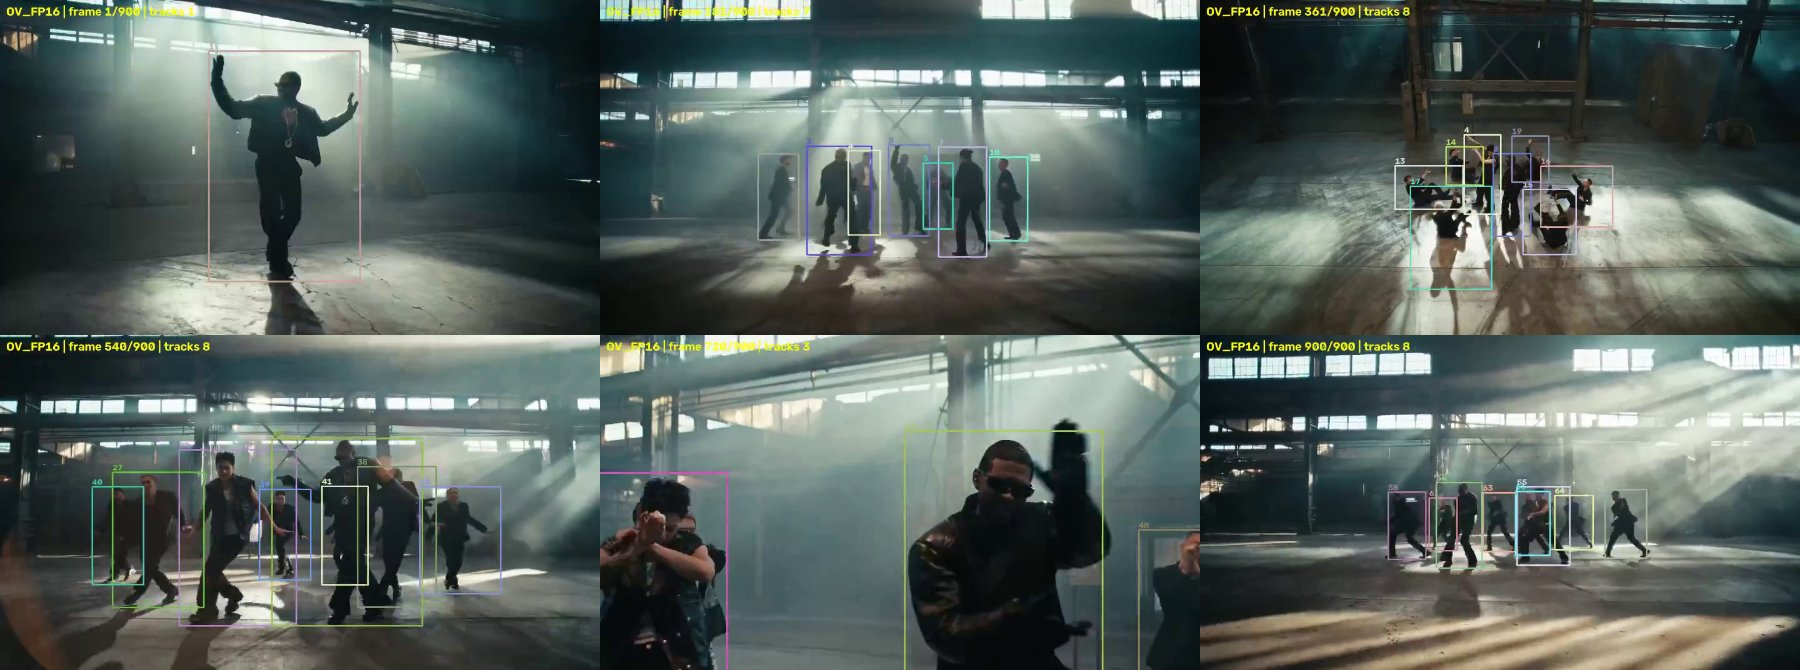

In [8]:
VIDEO_MAX_FRAMES = None
pt_ref_tracks = U.load_video_tracks(pt_results["video_reference_tracks"])
vid = dict(pt_results["video"])
for tag, run in (("OV_FP32", ov_fp32), ("OV_FP16", ov_fp16)):
    r = U.track_video(run, cfg, tag, max_frames=VIDEO_MAX_FRAMES)
    r["stats"].update(U.video_agreement(pt_ref_tracks[: len(r["tracks"])], r["tracks"]))
    vid[tag] = r["stats"]
    print(tag, {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r["stats"].items() if k != "mp4"})
display(Image(U.video_contact_sheet(vid["OV_FP16"]["mp4"], str(OUT / "images/video_ov_fp16_sheet.jpg")), width=1000))

## Optimize model using NNCF Post-training Quantization API
[back to top ⬆️](#Table-of-contents:)

[NNCF](https://github.com/openvinotoolkit/nncf) provides a suite of advanced algorithms for neural network inference
optimization in OpenVINO with minimal accuracy drop. We use 8-bit quantization in post-training mode (no fine-tuning)
to optimize the detector. The tracker is not a network and is unchanged.

The optimization process contains the following steps:

1. Create a Dataset for quantization: MOT17 **train-half** frames, which are disjoint from the val-half used for accuracy.
2. Run `nncf.quantize` to get an optimized model, starting from the **FP32 IR**.
3. Validate the result with MOTA / IDF1. If MOTA drops by **more than 2 points**, run
   `nncf.quantize_with_accuracy_control`.
4. Serialize the OpenVINO IR with `openvino.save_model`.

Options chosen after the NNCF options study (`scripts/quantize_int8.py`, variant v2):

| option | value | why |
|---|---|---|
| `preset` | `MIXED` | symmetric weights, asymmetric activations: SiLU outputs are not zero-centred |
| `ignored_scope` | box-decode tail (grid add, stride mul, `exp`, concat) | keeps box coordinates in float, analogous to `.*one2one.*` for YOLO26 |
| `fast_bias_correction` | `True` | full BiasCorrection caches ~27 GB of activations at 800×1440 (OOM on this 32 GB system) |
| `subset_size` | 300 | calibration frames |
| accuracy control | `max_drop=2.0`, `DropType.ABSOLUTE` (MOTA points) | only if the plain INT8 drop is > 2 |

Please select below whether you would like to run quantization to improve model inference speed.

In [9]:
IR_DIR.joinpath("INT8").mkdir(parents=True, exist_ok=True)
int8_model_det_path = IR_DIR / "INT8" / "bytetrack_x_mot17.xml"
int8_ac_model_det_path = IR_DIR / "INT8_accuracy_control" / "bytetrack_x_mot17.xml"
quantized_det_model = None

to_quantize = widgets.Checkbox(value=True, description="Quantization")
quantization_mode = widgets.Dropdown(
    options=[
        ("Default quantization (accuracy control only if ΔMOTA > 2)", "default"),
        ("Quantization with accuracy control", "accuracy_control"),
    ],
    value="default",
    description="Mode",
)

widgets.VBox([to_quantize, quantization_mode])

Let's load `skip magic` extension to skip quantization if `to_quantize` is not selected

In [10]:
if not Path("skip_kernel_extension.py").exists():
    import requests
    r = requests.get(
        url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/skip_kernel_extension.py",
    )
    open("skip_kernel_extension.py", "w").write(r.text)

%load_ext skip_kernel_extension

Prepare the calibration dataset for quantization: 300 evenly spaced MOT17 train-half frames, wrapped into an
`nncf.Dataset` object with a transformation function that applies the ByteTrack pre-processing.

In [11]:
%%skip not $to_quantize.value

N_CALIB = 300
train_half = U.mot17_train_half_frames()
image_files = [train_half[i] for i in np.linspace(0, len(train_half) - 1, N_CALIB).round().astype(int)]

def transform_fn(image_path):
    img = cv2.imread(str(image_path))
    x, _ = U.preprocess(img, cfg)            # letterbox 800x1440, BGR->RGB, /255, mean/std, NCHW f32
    return x

# keep the box-decode tail (everything after the head's final Transpose) in float
_ops = core.read_model(det_model_path).get_ordered_ops()
_t = max(i for i, o in enumerate(_ops) if o.get_type_name() == "Transpose")
decode_tail = [o.get_friendly_name() for o in _ops[_t:] if o.get_type_name() not in ("Constant", "Result")]
print(f"{len(image_files)} calibration frames | {len(decode_tail)} decode-tail ops kept in float")

300 calibration frames | 9 decode-tail ops kept in float


The `nncf.quantize` function provides an interface for model quantization. It requires an instance of the OpenVINO
Model and a quantization dataset. Optional parameters configure the quantization process: number of samples, preset,
ignored scope, and so on. YOLOX uses SiLU activations, which are non-ReLU and not zero-centred. They need asymmetric
quantization of activations, so we use the `mixed` preset: symmetric quantization of weights and asymmetric
quantization of activations.

For **accuracy control**, `validation_fn` runs the *whole tracking pipeline* (detector → NMS → BYTETracker) on a MOT17
val-half subset and returns MOTA. NNCF compiles the candidate models on **CPU** for this, so the subset is kept short:
`AC_SEQS` / `AC_FRAMES`.

>**Note**: Model post-training quantization is a time-consuming process. It takes ~5 min here (plain) and longer with
>accuracy control.

In [12]:
%%skip not $to_quantize.value

import nncf
import shutil
import openvino as ov

MAX_DROP = 2.0          # MOTA points (absolute)
AC_SEQS, AC_FRAMES = ["MOT17-09-FRCNN", "MOT17-02-FRCNN"], 150


def quantize_detector(use_accuracy_control, out_path):
    core = ov.Core()
    ov_model = core.read_model(det_model_path)            # FP32 IR

    quantization_dataset = nncf.Dataset(image_files, transform_fn)
    calibration_dataset = quantization_dataset
    PRESET = nncf.QuantizationPreset.MIXED
    FAST_BIAS_CORRECTION = True                           # full bias correction OOMs at 800x1440
    IGNORED_SCOPE = nncf.IgnoredScope(names=decode_tail, validate=False)

    # nncf with accuracy control
    if use_accuracy_control:
        import gc
        import motmetrics as mm
        from yolox.tracker.basetrack import BaseTrack

        DROP_TYPE = nncf.DropType.ABSOLUTE
        CALIB_SIZE = len(image_files)

        validation_seqs = U.mot17_val_half(AC_SEQS)
        for s in validation_seqs:
            s["frames"] = s["frames"][:AC_FRAMES]
        validation_dataset = nncf.Dataset(validation_seqs)          # one item = one MOT17 sequence

        def nncf_validation_fn(compiled_model, validation_subset) -> float:
            output = compiled_model.output(0)
            run = lambda x: compiled_model(x)[output]
            accs = []
            for s in validation_subset:
                BaseTrack._count = 0
                res, _, _ = U.track_sequence(run, s, cfg)
                gt_path = OUT / "accuracy" / "_gt_val_half" / f"{s['name']}.txt"
                U.BC.write_gt_val_half(s, str(gt_path))
                U.BC.write_results(str(OUT / "accuracy" / "_ac_tmp.txt"), res)
                gt = mm.io.loadtxt(str(gt_path), fmt="mot15-2D", min_confidence=1)
                ts = mm.io.loadtxt(str(OUT / "accuracy" / "_ac_tmp.txt"), fmt="mot15-2D", min_confidence=-1)
                accs.append(mm.utils.compare_to_groundtruth(gt, ts, "iou", distth=0.5))
            mota = 100 * float(mm.metrics.create().compute_many(accs, metrics=["mota"], generate_overall=True).loc["OVERALL", "mota"])
            print(f"[NNCF] MOTA = {mota:.2f}")
            gc.collect()
            return mota

    if not use_accuracy_control:
        quantized_det_model = nncf.quantize(
            ov_model,
            quantization_dataset,
            preset=PRESET,
            subset_size=len(image_files),
            fast_bias_correction=FAST_BIAS_CORRECTION,
            ignored_scope=IGNORED_SCOPE,
        )
    else:
        quantized_det_model = nncf.quantize_with_accuracy_control(
            ov_model,
            calibration_dataset=calibration_dataset,
            validation_dataset=validation_dataset,
            validation_fn=nncf_validation_fn,
            max_drop=MAX_DROP,
            drop_type=DROP_TYPE,
            preset=PRESET,
            subset_size=CALIB_SIZE,
            fast_bias_correction=FAST_BIAS_CORRECTION,
            ignored_scope=IGNORED_SCOPE,
        )

    print(f"Quantized model will be saved to {out_path}")
    out_path.parent.mkdir(parents=True, exist_ok=True)
    quantized_det_model.set_rt_info(json.dumps(cfg), ["bytetrack_config"])
    ov.save_model(quantized_det_model, str(out_path))
    shutil.copy(det_model_path.parent / "bytetrack_config.json", out_path.parent / "bytetrack_config.json")
    return quantized_det_model


use_accuracy_control = quantization_mode.value == "accuracy_control"
target = int8_ac_model_det_path if use_accuracy_control else int8_model_det_path
if not target.exists():
    t = time.perf_counter()
    quantized_det_model = quantize_detector(use_accuracy_control, target)
    print(f"quantization took {time.perf_counter() - t:.0f}s")
int8_path = target
m8 = core.read_model(int8_path)
print(f"INT8 IR: {int8_path} ({int8_path.with_suffix('.bin').stat().st_size / 1e6:.0f} MB) | "
      f"FakeQuantize nodes: {sum(o.get_type_name() == 'FakeQuantize' for o in m8.get_ordered_ops())}")

INFO:nncf:9 ignored nodes were found by names in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 376 __module.model.head/aten::permute/Transpose


INFO:nncf:Not adding activation input quantizer for operation: 386 aten::slice/Slice


INFO:nncf:Not adding activation input quantizer for operation: 387 aten::slice/Slice_1


INFO:nncf:Not adding activation input quantizer for operation: 388 aten::slice/Slice_2


...

INFO:nncf:Not adding activation input quantizer for operation: 400 aten::cat/Concat


Output()

Output()

Quantized model will be saved to ov_models/INT8/bytetrack_x_mot17.xml


quantization took 307s
INT8 IR: ov_models/INT8/bytetrack_x_mot17.xml (100 MB) | FakeQuantize nodes: 180


### Validate Quantized model inference
[back to top ⬆️](#Table-of-contents:)

The INT8 model goes through the same single-frame check and MOT17 val-half accuracy as FP32 / FP16. If the MOTA drop
versus OV FP32 is larger than `MAX_DROP` (2 points), the next cell falls back to
`nncf.quantize_with_accuracy_control` automatically.

OV INT8: 17.0 ms/frame | cosine vs PT FP32: raw 0.99866, scores 0.99977 | detections 14 (PT FP32: 15)


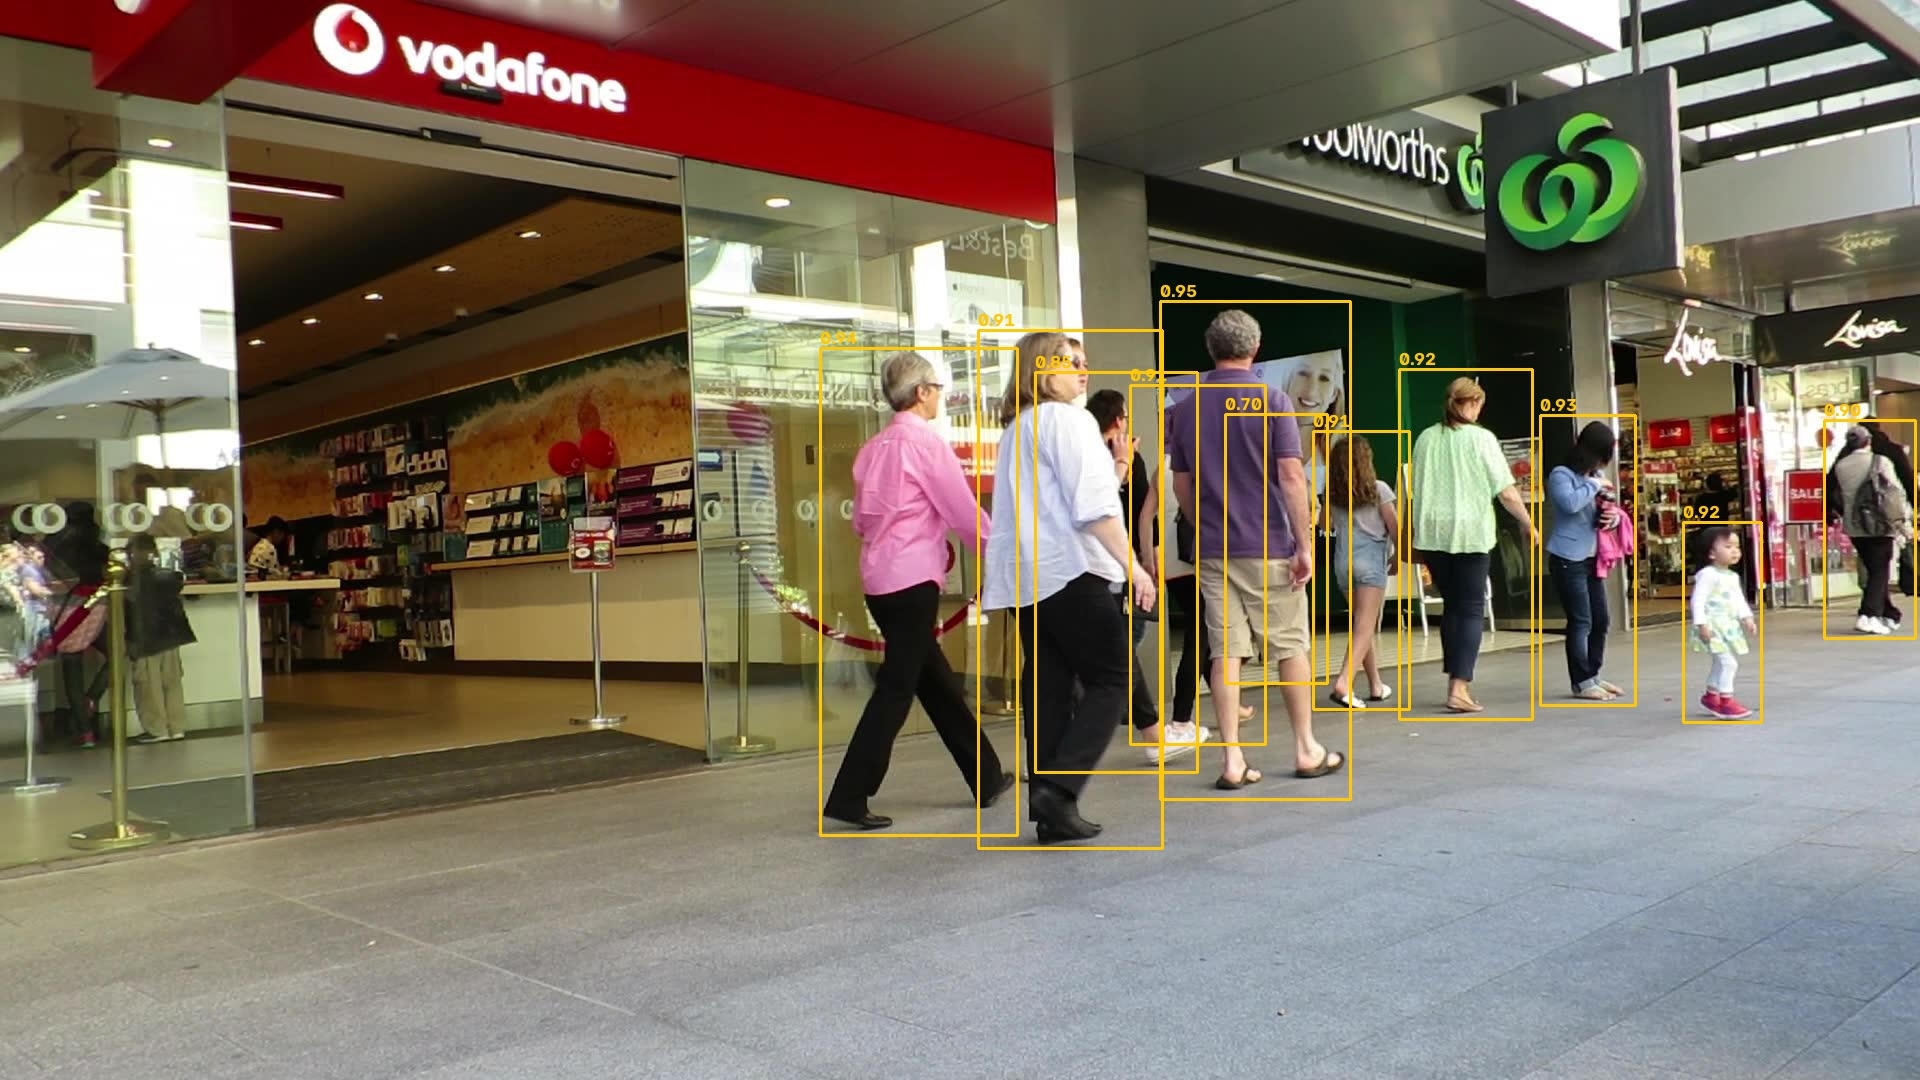

OV_INT8: MOTA 90.49 (drop vs OV FP32 -0.30) | IDF1 86.30 | IDs 168


In [13]:
%%skip not $to_quantize.value

ov_int8 = U.ov_runner(core, str(int8_path), device.value)
y8, ms8 = U.timeit(ov_int8, x0, n=10)
print(f"OV INT8: {ms8:.1f} ms/frame | cosine vs PT FP32: raw {U.cosine(y8, ref):.5f}, scores {U.score_cosine(y8, ref):.5f} | "
      f"detections {len(U.postprocess(y8, cfg))} (PT FP32: {len(U.postprocess(ref, cfg))})")
cv2.imwrite(str(OUT / "images/ov_int8_detections.jpg"), U.draw_dets(img0, U.postprocess(y8, cfg), r0))
display(Image(str(OUT / "images/ov_int8_detections.jpg"), width=900))

int8_tag = "OV_INT8_AC" if int8_path == int8_ac_model_det_path else "OV_INT8"
acc[int8_tag] = U.mot_eval(ov_int8, cfg, int8_tag, seqs=ACC_SEQS, verbose=False)
drop = acc["OV_FP32"]["MOTA"] - acc[int8_tag]["MOTA"]
print(f"{int8_tag}: MOTA {acc[int8_tag]['MOTA']:.2f} (drop vs OV FP32 {drop:+.2f}) | IDF1 {acc[int8_tag]['IDF1']:.2f} | IDs {acc[int8_tag]['IDs']}")

In [14]:
%%skip not $to_quantize.value

if drop > MAX_DROP and int8_tag == "OV_INT8":
    print(f"MOTA drop {drop:.2f} > {MAX_DROP} -> nncf.quantize_with_accuracy_control")
    if not int8_ac_model_det_path.exists():
        quantize_detector(True, int8_ac_model_det_path)
    int8_path, int8_tag = int8_ac_model_det_path, "OV_INT8_AC"
    ov_int8 = U.ov_runner(core, str(int8_path), device.value)
    acc[int8_tag] = U.mot_eval(ov_int8, cfg, int8_tag, seqs=ACC_SEQS, verbose=False)
    print(f"{int8_tag}: MOTA {acc[int8_tag]['MOTA']:.2f} (drop {acc['OV_FP32']['MOTA'] - acc[int8_tag]['MOTA']:+.2f})")
else:
    print(f"MOTA drop {drop:+.2f} <= {MAX_DROP}: plain nncf.quantize() meets the criterion, accuracy control is not needed")

MOTA drop -0.30 <= 2.0: plain nncf.quantize() meets the criterion, accuracy control is not needed


### Run INT8 on the video
[back to top ⬆️](#Table-of-contents:)

Same video, parameters and reference (PyTorch FP32 tracks) as above.

OV_INT8 {'tag': 'OV_INT8', 'frames': 900, 'shots': 8, 'unique_ids': 60, 'mean_tracks_per_frame': 6.04, 'cuts_with_ids_carried_across': 3, 'detector_ms_per_frame': 17.91, 'pipeline_fps': 23.02, 'video': 'JK_Standing_Next2U.mp4', 'fps': 30.0, 'IDF1_vs_ref': 85.88, 'MOTA_vs_ref': 96.11, 'IDsw_vs_ref': 23}


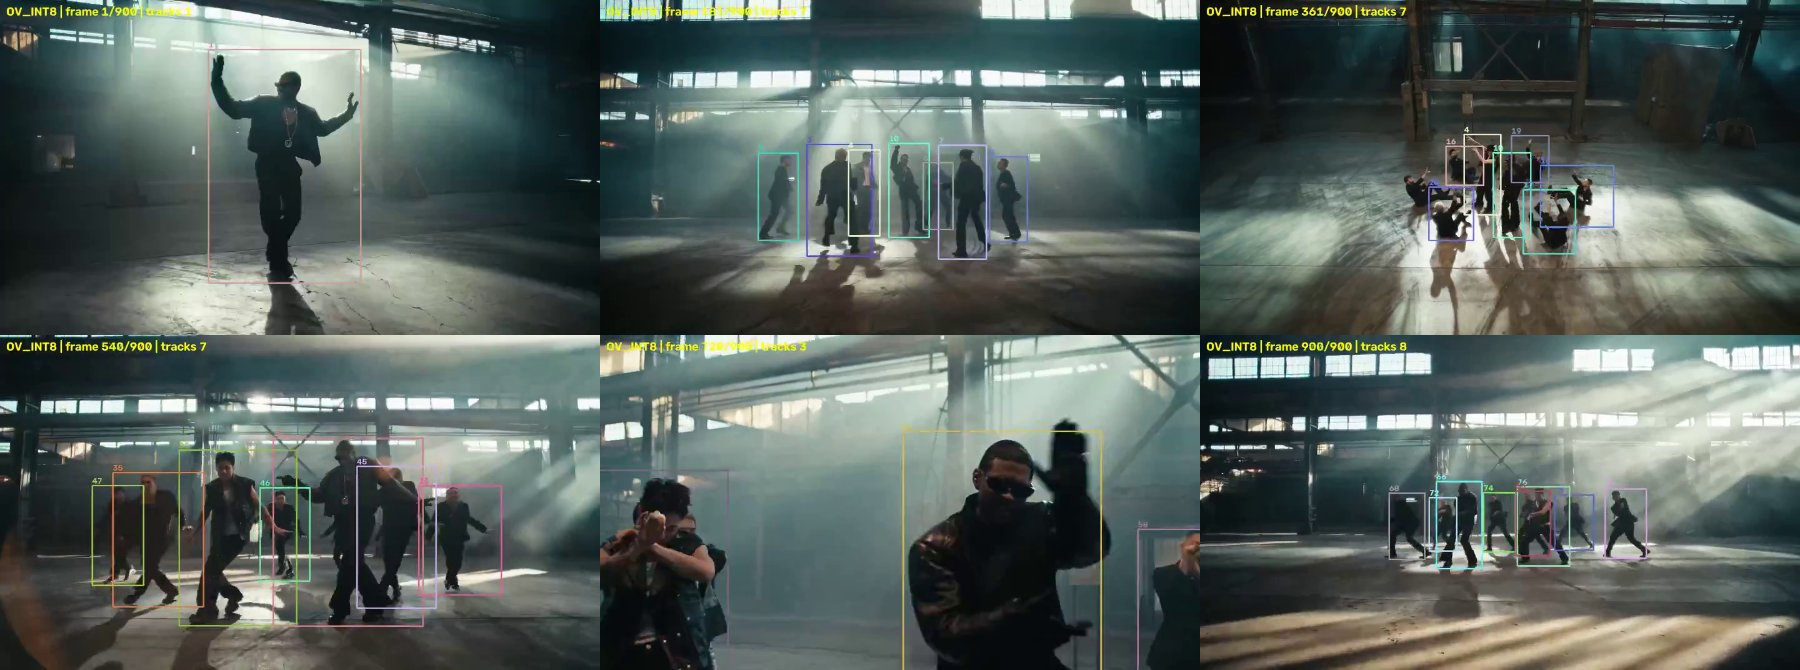

In [15]:
%%skip not $to_quantize.value

r = U.track_video(ov_int8, cfg, int8_tag, max_frames=VIDEO_MAX_FRAMES)
r["stats"].update(U.video_agreement(pt_ref_tracks[: len(r["tracks"])], r["tracks"]))
vid[int8_tag] = r["stats"]
print(int8_tag, {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r["stats"].items() if k != "mp4"})
display(Image(U.video_contact_sheet(vid[int8_tag]["mp4"], str(OUT / f"images/video_{int8_tag.lower()}_sheet.jpg")), width=1000))

## Compare performance of the models with benchmark_app
[back to top ⬆️](#Table-of-contents:)

Finally, use the OpenVINO [Benchmark Tool](https://docs.openvino.ai/2026/learn-openvino/openvino-samples/benchmark-tool.html)
to measure the **average latency** and **throughput (FPS)** of the FP32, FP16 and INT8 IRs. Two modes are measured,
matching the PyTorch notebook:
* `-hint latency -api sync`: 1 request, synchronous;
* `-hint tput`: async, with nireq chosen by the plugin. The PyTorch tput run used the same nireq; this is checked below.

`-ip f32` feeds f32 input like the PyTorch benchmark. benchmark_app's default for image inputs is u8. FP32 uses
`-infer_precision f32` on GPU. **`-b 1` is required:** without an explicit batch, `-hint tput` on GPU enables the
AUTO_BATCH plugin (16 requests, batched inference). The PyTorch benchmark cannot mirror that, so the comparison would
no longer be apples-to-apples.

> **Note**: For more accurate performance, run `benchmark_app` in a terminal after closing other applications, e.g.
> `benchmark_app -m <model_path> -d GPU -t 30 -b 1 -shape "[1,3,800,1440]" -hint tput -ip f32`.

In [16]:
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='GPU')

In [17]:
BENCH_TIME = pt_results["benchmark_settings"]["time_s"]
SHAPE = pt_results["benchmark_settings"]["shape"]
BENCH = OUT / "benchmark"; BENCH.mkdir(parents=True, exist_ok=True)
FP32_FLAGS = "-infer_precision f32" if device.value.startswith("GPU") else ""
# benchmark_app ships with the openvino pip package; use the one next to this kernel's python if it is not on PATH
benchmark_app = shutil.which("benchmark_app") or str(Path(sys.executable).parent / "benchmark_app")
print("benchmark_app | -t", BENCH_TIME, "| -shape", SHAPE)

benchmark_app | -t 15 | -shape [1,3,800,1440]


In [18]:
# Inference FP32 model (OpenVINO IR, executed in f32)
!$benchmark_app -m $det_model_path -d $device.value -b 1 -hint latency -api sync -ip f32 {FP32_FLAGS} -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/OV_FP32_sync.log | tail -12
!$benchmark_app -m $det_model_path -d $device.value -b 1 -hint tput -ip f32 {FP32_FLAGS} -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/OV_FP32_tput.log | tail -12

[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 219.72 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            78 iterations
[ INFO ] Duration:         15042.08 ms
[ INFO ] Latency:
[ INFO ]    Median:        192.57 ms
[ INFO ]    Average:       192.79 ms
[ INFO ]    Min:           191.69 ms
[ INFO ]    Max:           198.37 ms
[ INFO ] Throughput:   5.19 FPS


[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 269.96 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            84 iterations
[ INFO ] Duration:         16397.89 ms
[ INFO ] Latency:
[ INFO ]    Median:        775.54 ms
[ INFO ]    Average:       771.46 ms
[ INFO ]    Min:           450.89 ms
[ INFO ]    Max:           841.77 ms
[ INFO ] Throughput:   5.12 FPS


In [19]:
# Inference FP16 model (OpenVINO IR)
!$benchmark_app -m $fp16_model_path -d $device.value -b 1 -hint latency -api sync -ip f32 -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/OV_FP16_sync.log | tail -12
!$benchmark_app -m $fp16_model_path -d $device.value -b 1 -hint tput -ip f32 -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/OV_FP16_tput.log | tail -12

[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 83.26 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            545 iterations
[ INFO ] Duration:         15012.67 ms
[ INFO ] Latency:
[ INFO ]    Median:        27.19 ms
[ INFO ]    Average:       27.49 ms
[ INFO ]    Min:           26.91 ms
[ INFO ]    Max:           35.97 ms
[ INFO ] Throughput:   36.30 FPS


[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 42.80 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            540 iterations
[ INFO ] Duration:         15135.62 ms
[ INFO ] Latency:
[ INFO ]    Median:        109.61 ms
[ INFO ]    Average:       111.69 ms
[ INFO ]    Min:           30.57 ms
[ INFO ]    Max:           157.68 ms
[ INFO ] Throughput:   35.68 FPS


In [20]:
if int8_model_det_path.exists() or int8_ac_model_det_path.exists():
    # Inference INT8 model (OpenVINO IR)
    !$benchmark_app -m $int8_path -d $device.value -b 1 -hint latency -api sync -ip f32 -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/{int8_tag}_sync.log | tail -12
    !$benchmark_app -m $int8_path -d $device.value -b 1 -hint tput -ip f32 -shape "{SHAPE}" -t {BENCH_TIME} 2>&1 | tee {BENCH}/{int8_tag}_tput.log | tail -12

[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 19.85 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            925 iterations
[ INFO ] Duration:         15003.95 ms
[ INFO ] Latency:
[ INFO ]    Median:        16.16 ms
[ INFO ]    Average:       16.17 ms
[ INFO ]    Min:           16.09 ms
[ INFO ]    Max:           16.74 ms
[ INFO ] Throughput:   61.65 FPS


[ INFO ] Benchmarking in inference only mode (inputs filling are not included in measurement loop).
[ INFO ] First inference took 20.64 ms
[Step 11/11] Dumping statistics report
[ INFO ] Execution Devices:['GPU.0']
[ INFO ] Count:            944 iterations
[ INFO ] Duration:         15099.51 ms
[ INFO ] Latency:
[ INFO ]    Median:        63.89 ms
[ INFO ]    Average:       63.76 ms
[ INFO ]    Min:           19.04 ms
[ INFO ]    Max:           70.96 ms
[ INFO ] Throughput:   62.52 FPS


## Accuracy and performance: OpenVINO vs PyTorch
[back to top ⬆️](#Table-of-contents:)

All numbers were measured on the same machine with the same settings:
* **accuracy**: MOT17 val-half, identical host pipeline and tracker config;
* **performance**: `benchmark_app` for OpenVINO, and the benchmark_app-equivalent PyTorch benchmark with the same
  api / nireq / shape / duration / f32 I/O. **Average** latency is reported.

In [21]:
perf = dict(pt_results["benchmark"])
for c in ["OV_FP32", "OV_FP16"] + ([int8_tag] if "int8_tag" in globals() else []):
    for m in ("sync", "tput"):
        if (BENCH / f"{c}_{m}.log").exists():
            perf[f"{c}_{m}"] = U.parse_benchmark_log(BENCH / f"{c}_{m}.log")
nireq_ov = perf["OV_FP16_tput"]["nireq"]
print(f"benchmark_app -hint tput picked nireq={nireq_ov}; PyTorch tput used nireq={pt_results['benchmark_settings']['tput_nireq']}"
      + ("  -> apples-to-apples" if nireq_ov == pt_results["benchmark_settings"]["tput_nireq"] else "  -> MISMATCH: re-run PyTorch with this nireq"))

names = {"PT_FP32": "PyTorch FP32", "PT_FP16": "PyTorch FP16", "OV_FP32": "OpenVINO FP32 (f32)", "OV_FP16": "OpenVINO FP16",
         "OV_INT8": "OpenVINO INT8 (NNCF)", "OV_INT8_AC": "OpenVINO INT8 (NNCF, accuracy control)"}
table = []
for c in [k for k in names if k in acc]:
    a, s, t, v = acc[c], perf.get(f"{c}_sync"), perf.get(f"{c}_tput"), vid.get(c, {})
    table.append({"config": names[c], "MOTA": round(a["MOTA"], 2), "dMOTA_vs_PT_FP32": round(a["MOTA"] - acc["PT_FP32"]["MOTA"], 2),
                  "IDF1": round(a["IDF1"], 2), "IDs": a["IDs"],
                  "sync_avg_latency_ms": s and s["avg_ms"], "sync_fps": s and s["fps"],
                  "tput_fps": t and t["fps"], "tput_avg_latency_ms": t and t["avg_ms"], "tput_nireq": t and t["nireq"],
                  "video_IDF1_vs_PT_FP32": v.get("IDF1_vs_ref"), "speedup_sync_vs_PT_FP32": s and round(perf["PT_FP32_sync"]["avg_ms"] / s["avg_ms"], 2)})
f = lambda v, p=1: "-" if v is None else (f"{v:.{p}f}" if isinstance(v, float) else str(v))
rows = ["| Config | MOTA | ΔMOTA | IDF1 | IDs | sync AVG latency (ms) | sync FPS | tput FPS | tput AVG latency (ms) | video IDF1 vs PT FP32 | speed-up vs PT FP32 |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for r in table:
    rows.append(f"| {r['config']} | {r['MOTA']:.2f} | {r['dMOTA_vs_PT_FP32']:+.2f} | {r['IDF1']:.2f} | {r['IDs']} | {f(r['sync_avg_latency_ms'])} | "
                f"{f(r['sync_fps'], 2)} | {f(r['tput_fps'], 2)} | {f(r['tput_avg_latency_ms'])} | {f(r['video_IDF1_vs_PT_FP32'])} | {f(r['speedup_sync_vs_PT_FP32'], 2)}x |")
display(Markdown("\n".join(rows)))
json.dump({"table": table, "accuracy": acc, "benchmark": perf, "video": vid}, open(OUT / "ov_vs_pytorch_results.json", "w"), indent=2)
import csv
with open(OUT / "ov_vs_pytorch_results.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(table[0].keys())); w.writeheader(); w.writerows(table)
print("saved", OUT / "ov_vs_pytorch_results.json", "and .csv")

benchmark_app -hint tput picked nireq=4; PyTorch tput used nireq=4  -> apples-to-apples


| Config | MOTA | ΔMOTA | IDF1 | IDs | sync AVG latency (ms) | sync FPS | tput FPS | tput AVG latency (ms) | video IDF1 vs PT FP32 | speed-up vs PT FP32 |
|---|---|---|---|---|---|---|---|---|---|---|
| PyTorch FP32 | 90.20 | +0.00 | 86.57 | 175 | 189.0 | 5.29 | 4.90 | 804.0 | 100.0 | 1.00x |
| PyTorch FP16 | 90.23 | +0.04 | 86.47 | 180 | 52.8 | 18.94 | 18.77 | 211.9 | 100.0 | 3.58x |
| OpenVINO FP32 (f32) | 90.20 | +0.00 | 86.57 | 175 | 192.8 | 5.19 | 5.12 | 771.5 | 88.0 | 0.98x |
| OpenVINO FP16 | 90.24 | +0.05 | 86.83 | 179 | 27.5 | 36.30 | 35.68 | 111.7 | 86.1 | 6.88x |
| OpenVINO INT8 (NNCF) | 90.49 | +0.30 | 86.30 | 168 | 16.2 | 61.65 | 62.52 | 63.8 | 85.9 | 11.69x |

saved results/ov_vs_pytorch_results.json and .csv


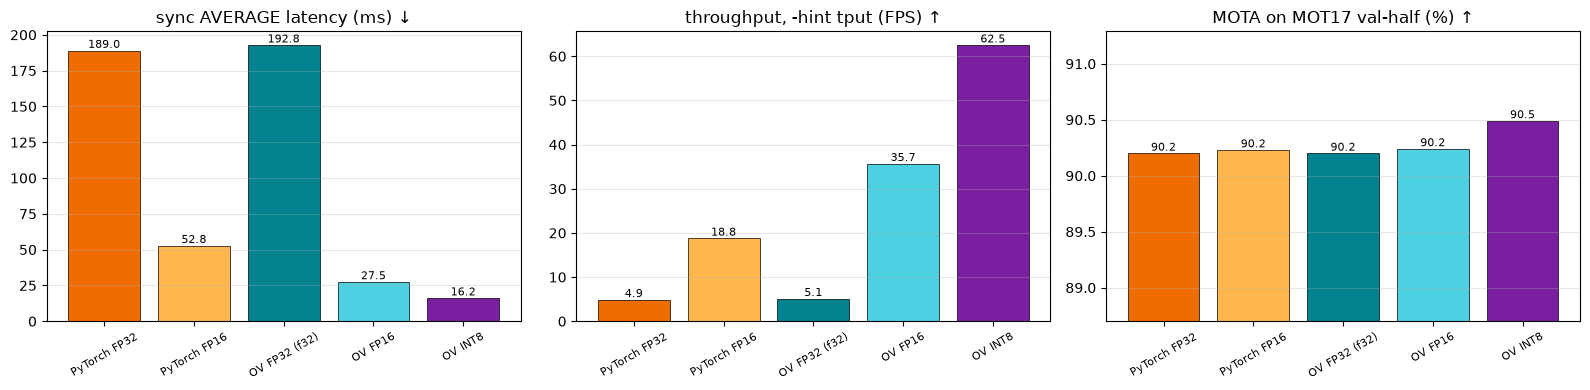

In [22]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
lbl = [r["config"].replace("OpenVINO", "OV").replace(" (NNCF, accuracy control)", " AC").replace(" (NNCF)", "") for r in table]
col = ["#ef6c00", "#ffb74d", "#00838f", "#4dd0e1", "#7b1fa2", "#ab47bc"][: len(table)]
for ax, key, title in ((axs[0], "sync_avg_latency_ms", "sync AVERAGE latency (ms) ↓"), (axs[1], "tput_fps", "throughput, -hint tput (FPS) ↑"),
                       (axs[2], "MOTA", "MOTA on MOT17 val-half (%) ↑")):
    vals = [r[key] or 0 for r in table]
    b = ax.bar(lbl, vals, color=col, edgecolor="k", lw=0.5); ax.bar_label(b, fmt="%.1f", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30, labelsize=8); ax.grid(axis="y", alpha=0.3)
    if key == "MOTA":
        ax.set_ylim(min(vals) - 1.5, max(vals) + 0.8)
plt.tight_layout(); plt.savefig(OUT / "images/ov_vs_pytorch.png", dpi=130); plt.show()